## Tema: Fatores associados ao desempenho das vendas: uma análise exploratória da base Olist
**Projeto Aplicado I — Pós-Graduação em Análise Estratégica de Dados**

**Integrantes:** Beatriz Maria Pereira Ribon e Cristina Satie Vatanabe

**Professor(a):**  Diego Mello da Silva e Marco Antônio Silva Pereira

Link acesso as bases de dados: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce?select=olist_order_payments_dataset.csv

# Artefato 1 – Entendimento do Negócio
## 1.1 Contextualização










O presente estudo tem como objetivo analisar os fatores que podem estar associados ao desempenho das vendas em uma operação de comércio eletrônico, utilizando dados reais disponibilizados pela Olist, empresa brasileira de tecnologia voltada ao comércio eletrônico. A base de dados reúne informações relacionadas a pedidos, clientes, produtos e itens comercializados, permitindo uma análise integrada do comportamento das vendas e de seus principais determinantes.

Para o desenvolvimento deste projeto, foram selecionadas quatro bases de dados do conjunto disponibilizado pela Olist: `olist_customers_dataset.csv`, `olist_order_items_dataset.csv`, `olist_orders_dataset.csv` e `olist_products_dataset.csv`. Essas bases foram escolhidas por apresentarem informações diretamente relacionadas ao objetivo do estudo, possibilitando identificar os pedidos realizados, os produtos comercializados, os valores das vendas, o perfil geográfico dos clientes e o período em que as compras ocorreram.

A base de clientes contém **99.441 registros e 5 atributos**, apresentando informações relacionadas aos consumidores e à sua localização. Para a análise, são utilizados principalmente o identificador do cliente e o estado em que a compra foi realizada.

A base de itens dos pedidos possui **112.650 registros e 7 atributos**, contendo informações sobre os produtos que compõem cada pedido. Entre as variáveis utilizadas estão o identificador do pedido, o identificador do produto, o preço do item e o valor do frete. Essas informações permitem calcular e analisar o valor das vendas e investigar a relação entre o valor comercializado e os custos de frete.

A base de pedidos apresenta **99.441 registros e 8 atributos**, contendo informações sobre os pedidos realizados pelos clientes. Entre as variáveis selecionadas estão o identificador do pedido, o identificador do cliente, o status do pedido e a data e hora da realização da compra. Esses dados possibilitam, principalmente, filtrar os pedidos considerados na análise e observar a evolução das vendas ao longo do tempo.

Por sua vez, a base de produtos possui **32.951 registros e 9 atributos**, sendo utilizada principalmente para identificar os produtos e suas respectivas categorias. A integração dessas informações com os itens dos pedidos permite analisar quais categorias apresentam maior participação no desempenho comercial.

A utilização conjunta dessas quatro bases possibilita a construção de uma base unificada, relacionando clientes, pedidos, produtos, categorias, valores e períodos de compra. Dessa forma, o estudo busca transformar os dados transacionais em informações que possam contribuir para uma melhor compreensão do desempenho das vendas e apoiar decisões comerciais mais assertivas.

A escolha dessa base se justifica pela riqueza e pelo volume das informações disponíveis, que permitem explorar diferentes dimensões do desempenho comercial. A partir da análise exploratória dos dados, pretende-se identificar padrões, diferenças entre categorias e regiões, comportamento das vendas ao longo do tempo e possíveis relações entre as variáveis disponíveis e o valor total comercializado.


## 1.2 Objetivos

### Objetivo Geral
Analisar a associação entre categoria do produto, estado do cliente, mês da compra e valor do frete com o valor de vendas dos pedidos entregues na base Olist.

### Objetivos Específicos
1. Identificar as categorias de produtos que apresentam maior participação no valor total de vendas dos pedidos entregues.
2. Comparar o valor total de vendas, a quantidade de pedidos e o ticket médio entre os estados dos clientes.
3. Descrever a variação mensal do número de pedidos, do valor total de vendas e do ticket médio ao longo do período disponível na base.
4. Avaliar se existe associação entre o valor do frete e o valor de vendas por pedido.
5. Comparar os padrões observados entre categorias, estados, meses e valores de frete para reconhecer quais dimensões merecem maior acompanhamento comercial.   
6. Interpretar os resultados de modo a indicar como os padrões identificados podem apoiar o planejamento e o monitoramento de decisões comerciais.
---
## 1.3 Pergunta de Negócio

> **Quais fatores — categoria do produto, estado do cliente, mês da compra e valor do frete — estão associados ao valor total de vendas dos pedidos entregues na base Olist?**

## 1.4 Questões para Investigação
1. Quais categorias de produtos concentram a maior parte da receita total da rede?
2. Quais estados dos clientes apresentam maior valor total de vendas e maior ticket médio?
3. Como o volume e o valor das vendas variam ao longo do tempo?
4. Existe associação entre o valor do frete e o valor de vendas por pedido?



# Artefato 2 – Entendimento dos Dados e Preparação dos Dados
## 2.1 Entendimento dos Dados

O arquivo .zip desse database contém 9 arquivos .csv:
- olist_customers_dataset.csv
- olist_geolocation_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv
- olist_sellers_dataset.csv
- product_category_name_translation.csv

Para nosso trabalho usaremos apenas 4 delas para podermos responder a pergunta de negócio.
- olist_customers_dataset.csv
- olist_order_items_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv

In [1]:
# O código a seguir permitirá acessar os arquivos do e-commerce da Olist diretamente do Kaggle.
# Para isso usaremos a biblioteca abaixo:

import kagglehub

# Importação da biblioteca abaixo para uso da função "os.path.join()".
import os

# Caminho onde o dataset foi salvo:
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

print("Caminho para os arquivos do dataset:", path)

# Uso da biblioteca pandas para manipular os dados.
import pandas as pd

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Caminho para os arquivos do dataset: /kaggle/input/brazilian-ecommerce


In [2]:
# Carregamento das bases de dados através do uso do "pd.read_csv" para leitura de cada arquivo dentro do Pandas.
# Utilizamos a função "os.path.join" para juntar o caminho salvo na variável "path" com o nome de cada arquivo.
# Assim o notebook funciona em qualquer ambiente, sem depender de um caminho fixo.
df_customer = pd.read_csv(os.path.join(path, 'olist_customers_dataset.csv'))
df_items    = pd.read_csv(os.path.join(path, 'olist_order_items_dataset.csv'))
df_orders   = pd.read_csv(os.path.join(path, 'olist_orders_dataset.csv'))
df_products = pd.read_csv(os.path.join(path, 'olist_products_dataset.csv'))

# Cópia dos dataframes originais por segurança:
customer_original = df_customer.copy()
items_original    = df_items.copy()
orders_original   = df_orders.copy()
products_original = df_products.copy()


### 2.1.1 Visualização inicial das bases
O uso das funções .head() e .tail() possibilitarão a visualização das 5 primeiras linhas e as 5 últimas linhas de cada tabela.

Tabela customer

In [3]:
df_customer.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [4]:
df_customer.tail()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,3937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,6764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS
99440,274fa6071e5e17fe303b9748641082c8,84732c5050c01db9b23e19ba39899398,6703,cotia,SP


Tabela items

In [5]:
df_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [6]:
df_items.tail()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:01,299.99,43.41
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:48,350.00,36.53
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:25,99.90,16.95
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:32,55.99,8.72
112649,fffe41c64501cc87c801fd61db3f6244,1,350688d9dc1e75ff97be326363655e01,f7ccf836d21b2fb1de37564105216cc1,2018-06-12 17:10:13,43.00,12.79


Tabela orders

In [7]:
df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
df_orders.tail()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


Tabela products

In [9]:
df_products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [10]:
df_products.tail()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
32946,a0b7d5a992ccda646f2d34e418fff5a0,moveis_decoracao,45.0,67.0,2.0,12300.0,40.0,40.0,40.0
32947,bf4538d88321d0fd4412a93c974510e6,construcao_ferramentas_iluminacao,41.0,971.0,1.0,1700.0,16.0,19.0,16.0
32948,9a7c6041fa9592d9d9ef6cfe62a71f8c,cama_mesa_banho,50.0,799.0,1.0,1400.0,27.0,7.0,27.0
32949,83808703fc0706a22e264b9d75f04a2e,informatica_acessorios,60.0,156.0,2.0,700.0,31.0,13.0,20.0
32950,106392145fca363410d287a815be6de4,cama_mesa_banho,58.0,309.0,1.0,2083.0,12.0,2.0,7.0


### 2.1.2 Dimensões do conjunto de dados

In [11]:
linhas_customer, colunas_customer = df_customer.shape

print(f'Número de registros da base customer : {linhas_customer}')
print(f'Número de atributos da base customer : {colunas_customer}\n')

linhas_items, colunas_items = df_items.shape

print(f'Número de registros da base items : {linhas_items}')
print(f'Número de atributos da base items : {colunas_items}\n')

linhas_ordes, colunas_ordes = df_orders.shape

print(f'Número de registros da base orders : {linhas_ordes}')
print(f'Número de atributos da base orders : {colunas_ordes}\n')

linhas_products, colunas_products = df_products.shape

print(f'Número de registros da base products : {linhas_products}')
print(f'Número de atributos da base products : {colunas_products}')

Número de registros da base customer : 99441
Número de atributos da base customer : 5

Número de registros da base items : 112650
Número de atributos da base items : 7

Número de registros da base orders : 99441
Número de atributos da base orders : 8

Número de registros da base products : 32951
Número de atributos da base products : 9


### 2.1.3 Variáveis disponíveis
O atributo "columns" será utilizado para auxiliar na identificação dos nomes de cada coluna em cada tabela.

In [12]:
df_customer.columns


Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')

In [13]:
df_items.columns


Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')

In [14]:
df_orders.columns


Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')

In [15]:
df_products.columns

Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')

### 2.1.4 Informações gerais do conjunto de dados
O método .info() dará apoio para entender se existem valores nulos e o tipo de cada coluna, além de trazer as informações de quantidade de linhas e colunas.

In [16]:
df_customer.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [17]:
df_items.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [18]:
df_orders.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [19]:
df_products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


### 2.1.5 Estatísticas Descritivas
O método .describe() retorna um resumo estatístico sobre as colunas numéricas.

Na tabela "df_customer" temos somente a coluna "customer_zip_code_prefix" classificada como numérica, porém ela representa os 5 primeiros dígitos do CEP do cliente, então não faria sentido analisar suas caracterísicas estatísticas.

A tabela "df_orders" por ter todos os atributos classificados como "object" será analisada no próximo item 2.1.6 Estatísticas das Variáveis Categóricas.



In [20]:
df_items.describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


Legenda:
* order_item_id: Número sequencial que identifica a quantidade de itens incluídos no mesmo pedido.   
* price: preço do item
* freight_value: valor do frete por item








In [21]:
df_products.describe()

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.000000,32341.000000,32341.000000,32949.000000,32949.000000,32949.000000,32949.000000
mean,48.476949,771.495285,2.188986,2276.472488,30.815078,16.937661,23.196728
std,10.245741,635.115225,1.736766,4282.038731,16.914458,13.637554,12.079047
min,5.000000,4.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,42.000000,339.000000,1.000000,300.000000,18.000000,8.000000,15.000000
50%,51.000000,595.000000,1.000000,700.000000,25.000000,13.000000,20.000000
75%,57.000000,972.000000,3.000000,1900.000000,38.000000,21.000000,30.000000
max,76.000000,3992.000000,20.000000,40425.000000,105.000000,105.000000,118.000000


Legenda:
* product_name_lenght: comprimento do nome do produto   
* product_description_lenght: comprimento da descrição do produto
* product_photos_qty: quantidade de fotos do produto
* product_weight_g: peso do produto em gramas
* product_length_cm: comprimento do produto em centímetros
* product_height_cm: altura do produto em centímetros
* product_width_cm: largura do produto em centímetros

### 2.1.6 Estatísticas das Variáveis Categóricas

In [22]:
df_customer.describe(include='object')

,customer_id,customer_unique_id,customer_city,customer_state
count,99441,99441,99441,99441
unique,99441,96096,4119,27
top,274fa6071e5e17fe303b9748641082c8,8d50f5eadf50201ccdcedfb9e2ac8455,sao paulo,SP
freq,1,17,15540,41746


Legenda:
* customer_id: Chave para o conjunto de dados do cliente. Cada pedido possui um customer id único.
* customer_unique_id: Identificador único de um cliente.   
* customer_city: nome da cidade do cliente
* customer_state: estado_do_cliente

In [23]:
df_items.describe(include='object')

,order_id,product_id,seller_id,shipping_limit_date
count,112650,112650,112650,112650
unique,98666,32951,3095,93318
top,8272b63d03f5f79c56e9e4120aec44ef,aca2eb7d00ea1a7b8ebd4e68314663af,6560211a19b47992c3666cc44a7e94c0,2017-07-21 18:25:23
freq,21,527,2033,21


Legenda:
* order_id: identificador único do pedido   
* product_id: identificador único do produto     
* seller_id : identificador único do vendedor
* shipping_limit_date: Mostra a data limite de envio do vendedor para que ele entregue o pedido ao parceiro logístico.

In [24]:
df_orders.describe(include='object')

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99441,99441,99441,99281,97658,96476,99441
unique,99441,99441,8,98875,90733,81018,95664,459
top,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-08-02 12:06:07,2018-02-27 04:31:10,2018-05-09 15:48:00,2018-05-14 20:02:44,2017-12-20 00:00:00
freq,1,1,96478,3,9,47,3,522


Legenda:   
* order_status: Referência ao status do pedido (entregue, enviado, etc.)
* order_purchase_timestamp: Exibe o registro de data e hora da compra.
* order_approved_at: Exibe o registro de data e hora da aprovação do pagamento.
* order_delivered_carrier_date: Exibe o registro de data e hora da postagem do pedido. Indica quando ele foi entregue ao parceiro logístico.
* order_delivered_customer_date: Mostra a data real de entrega do pedido ao cliente.
* order_estimated_delivery_date: Exibe a data de entrega estimada que foi informada ao cliente no momento da compra.





In [25]:
df_products.describe(include='object')

,product_id,product_category_name
count,32951,32341
unique,32951,73
top,106392145fca363410d287a815be6de4,cama_mesa_banho
freq,1,3029


Legenda:   
* product_category_name: Categoria do produto

In [26]:
# Possíveis conteúdos das variáveis categóricas da tabela customer
colunas_categoricas_customer = df_customer.select_dtypes(include='object').columns
for colunas_customer in colunas_categoricas_customer:
    print(f'\n{colunas_customer}')
    print('-'*len(colunas_customer))
    print(df_customer[colunas_customer].unique())


customer_id
-----------
['06b8999e2fba1a1fbc88172c00ba8bc7' '18955e83d337fd6b2def6b18a428ac77'
 '4e7b3e00288586ebd08712fdd0374a03' ... '5e28dfe12db7fb50a4b2f691faecea5e'
 '56b18e2166679b8a959d72dd06da27f9' '274fa6071e5e17fe303b9748641082c8']

customer_unique_id
------------------
['861eff4711a542e4b93843c6dd7febb0' '290c77bc529b7ac935b93aa66c333dc3'
 '060e732b5b29e8181a18229c7b0b2b5e' ... 'e9f50caf99f032f0bf3c55141f019d99'
 '73c2643a0a458b49f58cea58833b192e' '84732c5050c01db9b23e19ba39899398']

customer_city
-------------
['franca' 'sao bernardo do campo' 'sao paulo' ... 'monte bonito'
 'sao rafael' 'eugenio de castro']

customer_state
--------------
['SP' 'SC' 'MG' 'PR' 'RJ' 'RS' 'PA' 'GO' 'ES' 'BA' 'MA' 'MS' 'CE' 'DF'
 'RN' 'PE' 'MT' 'AM' 'AP' 'AL' 'RO' 'PB' 'TO' 'PI' 'AC' 'SE' 'RR']


In [27]:
# Possíveis conteúdos das variáveis categóricas da tabela items
colunas_categoricas_items = df_items.select_dtypes(include='object').columns
for colunas_items in colunas_categoricas_items:
    print(f'\n{colunas_items}')
    print('-'*len(colunas_items))
    print(df_items[colunas_items].unique())


order_id
--------
['00010242fe8c5a6d1ba2dd792cb16214' '00018f77f2f0320c557190d7a144bdd3'
 '000229ec398224ef6ca0657da4fc703e' ... 'fffce4705a9662cd70adb13d4a31832d'
 'fffe18544ffabc95dfada21779c9644f' 'fffe41c64501cc87c801fd61db3f6244']

product_id
----------
['4244733e06e7ecb4970a6e2683c13e61' 'e5f2d52b802189ee658865ca93d83a8f'
 'c777355d18b72b67abbeef9df44fd0fd' ... 'dd469c03ad67e201bc2179ef077dcd48'
 'bbe7651fef80287a816ead73f065fc4b' '350688d9dc1e75ff97be326363655e01']

seller_id
---------
['48436dade18ac8b2bce089ec2a041202' 'dd7ddc04e1b6c2c614352b383efe2d36'
 '5b51032eddd242adc84c38acab88f23d' ... '3fefda3299e6dfaea3466ef346a3571a'
 '80ceebb4ee9b31afb6c6a916a574a1e2' '3e35a8bb43569389d3cebef0ce820f69']

shipping_limit_date
-------------------
['2017-09-19 09:45:35' '2017-05-03 11:05:13' '2018-01-18 14:48:30' ...
 '2017-10-30 17:14:25' '2017-08-21 00:04:32' '2018-06-12 17:10:13']


In [28]:
# Possíveis conteúdos das variáveis categóricas da tabela orders
colunas_categoricas_orders = df_orders.select_dtypes(include='object').columns
for colunas_orders in colunas_categoricas_orders:
    print(f'\n{colunas_orders}')
    print('-'*len(colunas_orders))
    print(df_orders[colunas_orders].unique())


order_id
--------
['e481f51cbdc54678b7cc49136f2d6af7' '53cdb2fc8bc7dce0b6741e2150273451'
 '47770eb9100c2d0c44946d9cf07ec65d' ... '83c1379a015df1e13d02aae0204711ab'
 '11c177c8e97725db2631073c19f07b62' '66dea50a8b16d9b4dee7af250b4be1a5']

customer_id
-----------
['9ef432eb6251297304e76186b10a928d' 'b0830fb4747a6c6d20dea0b8c802d7ef'
 '41ce2a54c0b03bf3443c3d931a367089' ... '1aa71eb042121263aafbe80c1b562c9c'
 'b331b74b18dc79bcdf6532d51e1637c1' 'edb027a75a1449115f6b43211ae02a24']

order_status
------------
['delivered' 'invoiced' 'shipped' 'processing' 'unavailable' 'canceled'
 'created' 'approved']

order_purchase_timestamp
------------------------
['2017-10-02 10:56:33' '2018-07-24 20:41:37' '2018-08-08 08:38:49' ...
 '2017-08-27 14:46:43' '2018-01-08 21:28:27' '2018-03-08 20:57:30']

order_approved_at
-----------------
['2017-10-02 11:07:15' '2018-07-26 03:24:27' '2018-08-08 08:55:23' ...
 '2017-08-27 15:04:16' '2018-01-08 21:36:21' '2018-03-09 11:20:28']

order_delivered_carrier_date
--

In [29]:
# Possíveis conteúdos das variáveis categóricas da tabela products
colunas_categoricas_products = df_products.select_dtypes(include='object').columns
for colunas_products in colunas_categoricas_products:
    print(f'\n{colunas_products}')
    print('-'*len(colunas_products))
    print(df_products[colunas_products].unique())


product_id
----------
['1e9e8ef04dbcff4541ed26657ea517e5' '3aa071139cb16b67ca9e5dea641aaa2f'
 '96bd76ec8810374ed1b65e291975717f' ... '9a7c6041fa9592d9d9ef6cfe62a71f8c'
 '83808703fc0706a22e264b9d75f04a2e' '106392145fca363410d287a815be6de4']

product_category_name
---------------------
['perfumaria' 'artes' 'esporte_lazer' 'bebes' 'utilidades_domesticas'
 'instrumentos_musicais' 'cool_stuff' 'moveis_decoracao'
 'eletrodomesticos' 'brinquedos' 'cama_mesa_banho'
 'construcao_ferramentas_seguranca' 'informatica_acessorios'
 'beleza_saude' 'malas_acessorios' 'ferramentas_jardim'
 'moveis_escritorio' 'automotivo' 'eletronicos' 'fashion_calcados'
 'telefonia' 'papelaria' 'fashion_bolsas_e_acessorios' 'pcs'
 'casa_construcao' 'relogios_presentes'
 'construcao_ferramentas_construcao' 'pet_shop' 'eletroportateis'
 'agro_industria_e_comercio' nan 'moveis_sala' 'sinalizacao_e_seguranca'
 'climatizacao' 'consoles_games' 'livros_interesse_geral'
 'construcao_ferramentas_ferramentas' 'fashion_underwe

In [30]:
# Frequências das Variáveis categóricas da tabela customer
for coluna_customer in colunas_categoricas_customer:
    print(f'\n{"="*50}')
    print(coluna_customer)
    print("="*50)
    print(df_customer[coluna_customer].value_counts())


customer_id
customer_id
274fa6071e5e17fe303b9748641082c8    1
e5ed7280cd1a3ac2ba29fd6650d8867c    1
c6ece8a5137f3c9c3a3a12302a19a2ac    1
821a7275a08f32975caceff2e08ea262    1
5eef6cce1f34954c9e7004332388ccc7    1
                                   ..
879864dab9bc3047522c92c82e1212b8    1
4f2d8ab171c80ec8364f7c12e35b23ad    1
b2b6027bc5c5109e529d4dc6358b12c3    1
4e7b3e00288586ebd08712fdd0374a03    1
18955e83d337fd6b2def6b18a428ac77    1
Name: count, Length: 99441, dtype: int64

customer_unique_id
customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    17
3e43e6105506432c953e165fb2acf44c     9
ca77025e7201e3b30c44b472ff346268     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
6469f99c1f9dfae7733b25662e7f1782     7
                                    ..
4f83c83b7ff5b544a8c75dcb8ad66e2e     1
3fe413dde400746c53c5d0d38b266ca2     1
289e1d1ce11a14bb169775d58ad2f1c2     1
ec83d060d9a0abba4b409c544c744c2f     1
211e4234ffca5cec9b0ab183a1009256     1
Name: count, Length: 96096, dtype: int64

custom

In [31]:
# Frequências das Variáveis categóricas da tabela items
for coluna_items in colunas_categoricas_items:
    print(f'\n{"="*50}')
    print(coluna_items)
    print("="*50)
    print(df_items[coluna_items].value_counts())


order_id
order_id
8272b63d03f5f79c56e9e4120aec44ef    21
1b15974a0141d54e36626dca3fdc731a    20
ab14fdcfbe524636d65ee38360e22ce8    20
9ef13efd6949e4573a18964dd1bbe7f5    15
428a2f660dc84138d969ccd69a0ab6d5    15
                                    ..
5a082b558a3798d3e36d93bfa8ca1eae     1
5a07264682e0b8fbb3f166edbbffc6e8     1
5a071192a28951b76774e5a760c8c9b7     1
5a06fc966a12b41bf401b344464fd4b1     1
5a0e5ad33542c79b10be87a344ee0086     1
Name: count, Length: 98666, dtype: int64

product_id
product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
                                   ... 
038c0dd7c1e48a1588f8919a0c305727      1
aa20709d44e96059764f1b0386d3bcfa      1
9ae3dacfd2327107a1e28274fac25a4e      1
0c398b245c9b74ef2bf4343b6fe73237      1
446295cf6f689d4db477145815362608      1
Name: count, Length: 32951, dtype: int64

seller

In [32]:
# Frequências das Variáveis categóricas da tabela orders
for coluna_orders in colunas_categoricas_orders:
    print(f'\n{"="*50}')
    print(coluna_orders)
    print("="*50)
    print(df_orders[coluna_orders].value_counts())


order_id
order_id
66dea50a8b16d9b4dee7af250b4be1a5    1
6ec4642f9993cc34f826cfb9068e5a2f    1
38e9133ce29f6bbe35aed9c3863dce01    1
dfc6eb45a2753ed9e6c6ef4987b44503    1
6f46d42016226f77893ed3978d6903d0    1
                                   ..
a4591c265e18cb1dcee52889e2d8acc3    1
ad21c59c0840e6cb83a9ceb5573f8159    1
949d5b44dbf5de918fe9c16f97b45f8a    1
47770eb9100c2d0c44946d9cf07ec65d    1
53cdb2fc8bc7dce0b6741e2150273451    1
Name: count, Length: 99441, dtype: int64

customer_id
customer_id
edb027a75a1449115f6b43211ae02a24    1
f00bb12620b7b232233cace1b229db18    1
ad312389a098ceff46ce92c4595c06d0    1
a046c690e0564ffde0ce611b5eee2c30    1
3803547f820b1e10b7ad9c7985f06753    1
                                   ..
503740e9ca751ccdda7ba28e9ab8f608    1
8ab97904e6daea8866dbdbc4fb7aad2c    1
f88197465ea7920adcdbec7375364d82    1
41ce2a54c0b03bf3443c3d931a367089    1
b0830fb4747a6c6d20dea0b8c802d7ef    1
Name: count, Length: 99441, dtype: int64

order_status
order_status
delivered  

In [33]:
# Frequências das Variáveis categóricas da tabela products
for coluna_products in colunas_categoricas_products:
    print(f'\n{"="*50}')
    print(coluna_products)
    print("="*50)
    print(df_products[coluna_products].value_counts())


product_id
product_id
106392145fca363410d287a815be6de4    1
1e9e8ef04dbcff4541ed26657ea517e5    1
3aa071139cb16b67ca9e5dea641aaa2f    1
96bd76ec8810374ed1b65e291975717f    1
cef67bcfe19066a932b7673e239eb23d    1
                                   ..
03b63c5fc16691530586ae020c345514    1
14aa47b7fe5c25522b47b4b29c98dcb9    1
8c92109888e8cdf9d66dc7e463025574    1
37cc742be07708b53a98702e77a21a02    1
2548af3e6e77a690cf3eb6368e9ab61e    1
Name: count, Length: 32951, dtype: int64

product_category_name
product_category_name
cama_mesa_banho                  3029
esporte_lazer                    2867
moveis_decoracao                 2657
beleza_saude                     2444
utilidades_domesticas            2335
                                 ... 
fashion_roupa_infanto_juvenil       5
casa_conforto_2                     5
pc_gamer                            3
seguros_e_servicos                  2
cds_dvds_musicais                   1
Name: count, Length: 73, dtype: int64


### 2.1.7 Síntese do Entendimento dos Dados

| Tabela | Registros | Atributos |
| --- | --- | --- |
| Customer | 99441 | 5 |
| Items | 112650 | 7 |
| Orders | 99441 | 8 |
| Products | 32951 | 9 |

Nas 4 tabelas temos predomínio de variáveis categóricas do tipo object e classificadas como:

*   5 variáveis identificadoras: customer_id, customer_unique_id, order_id, product_id e seller_id.
*   4 variáveis categóricas: customer_city, customer_state, order_status e product_category_name.
*   6 variáveis de data: shipping_limit_date, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date e order_estimated_delivery_date.

Em relação às variáveis numéricas temos a quantidade de 11: customer_zip_code_prefix, order_item_id, Price, freight_value, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm e product_width_cm.

Para responder a pergunta de negócio e as questões para investigação, foram selecionadas algumas variáveis em cada tabela com o intuito de:

*   Identificar os pedidos
*   Relacionar tabelas
*   Filtrar os pedidos entregues
*   Calcular o valor das vendas e do frete
*   Identificar a categoria dos produtos
*   Identificar os Estados dos clientes
*   Identificar o período de compra

As demais variáveis não foram consideradas para esse trabalho, porque não possuem relação direta com o objetivo da análise.

**Tabela customer**: representa os dados sobre o cliente e sua localização.

Uma linha por cliente.

Dos 5 atributos utilizaremos 2:

*   customer_id: chave de ligação do cliente ao pedido.
*   customer_state: identifica em qual estado o cliente fez a compra.



**Tabela items**: apresenta os itens que compõem cada pedido, além de valores de preços e fretes.

Uma linha por item do pedido.

Dos 7 atributos utilizaremos 5:
*   order_id: chave de ligação do item ao pedido.
*   order_item_id: identificação individual de cada unidade vendida.
*   product_id: chave de ligação do item ao produto.
*   price: saber o preço do item permite calcular o valor da venda.
*   freight_value: podemos analisar a relação do valor do frete e o valor das vendas.





**Tabela orders**: traz as informações sobre os pedidos dos clientes em relação ao status da entrega e o perído da compra.

Uma linha por pedido

Observação: um pedido pode ter vários itens.

Dos 8 atributos utilizaremos 4:
*   order_id: chave de ligação do item ao pedido.
*   customer_id: chave de ligação do cliente ao pedido.
*   order_status: mostra o status do pedido do cliente.
*   order_purchase_timestamp: permite identificar a data da compra.

**Tabela products**: contém informações sobre os produtos comercializados pela Olist por categoria.

Uma linha por produto.

Dos 9 atributos utilizaremos 2:
*   product_id: chave de ligação do item ao produto.
*   product_category_name: identifica a classificação de cada produto.


## Unidades de Análise
## Unidade de análise: pedido
Na base de pedidos, cada linha representará um pedido entregue, identificado por order_id. Como um mesmo pedido pode possuir vários itens, os registros da tabela items serão agrupados por order_id para calcular:

•	valor_vendas: soma dos preços dos itens (price) do pedido.

•	valor_frete: soma dos valores de frete (freight_value) dos itens do pedido.

Essa base será utilizada para analisar o valor de vendas por estado do cliente, a variação mensal das vendas, o ticket médio e a associação entre frete e valor de vendas.
## Unidade de análise: item do pedido
Na base de itens, cada linha representará um item associado a um pedido. Como um pedido pode conter vários produtos, o mesmo order_id poderá aparecer mais de uma vez. Essa repetição é esperada e não representa necessariamente uma duplicidade.

Essa base será relacionada à tabela de produtos por meio de product_id para identificar a categoria de cada item. Ela será utilizada para analisar quais categorias concentram maior valor de vendas.


## 2.2 Preparação dos Dados

Nessa etapa verificaremos se temos registros ausentes, duplicados e incompatíveis, visando tratá-los para construir 2 bases para seguir com a etapa de análise exploratória (Artefato 3).


In [34]:
#Criação de cópias de dataframes somente com as colunas necessárias
customers_reduzida = df_customer[[
    'customer_id',
    'customer_state'
]].copy()

items_reduzida = df_items[[
    'order_id',
    'order_item_id',
    'product_id',
    'price',
    'freight_value'
]].copy()

orders_reduzida = df_orders[[
    'order_id',
    'customer_id',
    'order_status',
    'order_purchase_timestamp'
]].copy()

products_reduzida = df_products[[
    'product_id',
    'product_category_name'
]].copy()

### 2.2.1 Verificação dos tipos das variáveis

In [35]:
# Foi usado o atributo .dtypes que retorna o tipo de dados contido em cada coluna
print('Tabela customer:')
customers_reduzida.dtypes

Tabela customer:


,0
customer_id,object
customer_state,object


In [36]:
print('Tabela items:')
items_reduzida.dtypes

Tabela items:


,0
order_id,object
order_item_id,int64
product_id,object
price,float64
freight_value,float64


In [37]:
print('Tabela orders:')
orders_reduzida.dtypes

Tabela orders:


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object


In [38]:
print('Tabela products:')
products_reduzida.dtypes

Tabela products:


,0
product_id,object
product_category_name,object


### 2.2.2 Verificação de registros duplicados

In [39]:
#Verificação de valores duplicados
print('Linhas completamente duplicadas em customer:')
print(customers_reduzida.duplicated().sum())

print('Linhas completamente duplicadas em items:')
print(items_reduzida.duplicated().sum())

print('Linhas completamente duplicadas em orders:')
print(orders_reduzida.duplicated().sum())

print('Linhas completamente duplicadas em products:')
print(products_reduzida.duplicated().sum())

Linhas completamente duplicadas em customer:
0
Linhas completamente duplicadas em items:
0
Linhas completamente duplicadas em orders:
0
Linhas completamente duplicadas em products:
0


### 2.2.3 Verificação dos valores ausentes
O uso da função .isna() permite varrer a tabela célula por célula avaliando se o valor é nulo(True) ou não(False) e o .sum() vai somando o cumulativo dos valores 1 (True).

In [40]:
print('Ausentes em customer:')
display(customers_reduzida.isna().sum())

Ausentes em customer:


,0
customer_id,0
customer_state,0


In [41]:
print('Ausentes em items:')
display(items_reduzida.isna().sum())

Ausentes em items:


,0
order_id,0
order_item_id,0
product_id,0
price,0
freight_value,0


In [42]:
print('Ausentes em orders:')
display(orders_reduzida.isna().sum())

Ausentes em orders:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0


In [43]:
print('Ausentes em orders:')
display(products_reduzida.isna().sum())

Ausentes em orders:


,0
product_id,0
product_category_name,610


### 2.2.4 Investigação das variáveis incompatíveis

### Conversão de datas da variável order_purchase_timestamp

In [44]:
# Tipo atual e amostra de valores de order_purchase_timestamp
print('Tipo atual:', orders_reduzida['order_purchase_timestamp'].dtype)
orders_reduzida['order_purchase_timestamp'].head()

Tipo atual: object


,order_purchase_timestamp
0,2017-10-02 10:56:33
1,2018-07-24 20:41:37
2,2018-08-08 08:38:49
3,2017-11-18 19:28:06
4,2018-02-13 21:18:39


In [45]:
# Conversão da variável order_purchase_timestamp de texto(object) para datetime.
# Isso permitirá fazer as operações temporais, como extração de períodos.
orders_reduzida['order_purchase_timestamp'] = pd.to_datetime(orders_reduzida['order_purchase_timestamp'])

In [46]:
# Verificando se a conversão foi bem-sucedida
print('Novo tipo:', orders_reduzida['order_purchase_timestamp'].dtype)
orders_reduzida.dtypes

Novo tipo: datetime64[ns]


,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]


### Conversão de número da variável price e freight_value

In [47]:
# Tipo atual das variáveis price e freight_value
print('Tipos atuais:')
print(items_reduzida[['price', 'freight_value']].dtypes)
items_reduzida[['price', 'freight_value']].head()


Tipos atuais:
price            float64
freight_value    float64
dtype: object


,price,freight_value
0,58.90,13.29
1,239.90,19.93
2,199.00,17.87
3,12.99,12.79
4,199.90,18.14


In [48]:
# Confirmação/conversão das variáveis price e freight_value para numérico
items_reduzida['price'] = pd.to_numeric(items_reduzida['price'], errors='coerce')
items_reduzida['freight_value'] = pd.to_numeric(items_reduzida['freight_value'], errors='coerce')

# Verificando se surgiram valores ausentes após a conversão (indicaria valores não numéricos)
print('Ausentes após conversão:')
print(items_reduzida[['price', 'freight_value']].isna().sum())

print('\nTipos finais:')
print(items_reduzida[['price', 'freight_value']].dtypes)

Ausentes após conversão:
price            0
freight_value    0
dtype: int64

Tipos finais:
price            float64
freight_value    float64
dtype: object


### 2.2.5 Tratamento dos valores ausentes

In [49]:
# Confirmando os valores ausentes antes do tratamento
print('Ausentes em products_reduzida:')
display(products_reduzida.isna().sum())

Ausentes em products_reduzida:


,0
product_id,0
product_category_name,610


In [50]:
# Tratamento dos valores ausentes em product_category_name
# Foi decidido preencher os valores ausentes com o uso da função .fillna com a informação "categoria_nao_informada"
products_reduzida['product_category_name'] = products_reduzida['product_category_name'].fillna('categoria_nao_informada')

# Verificando se o tratamento foi bem-sucedido
print('Ausentes em products_reduzida após tratamento:')
display(products_reduzida.isna().sum())

Ausentes em products_reduzida após tratamento:


,0
product_id,0
product_category_name,0


### 2.2.6 Tratamento dos valores duplicados

In [51]:
# Com order_item_id preservado, cada linha de items_reduzida passa a ser identificada pela combinação (order_id, order_item_id).
# Vamos confirmar que essa combinação é de fato única e reavaliar a duplicidade completa de linhas.

duplicadas_completas = items_reduzida.duplicated().sum()
duplicadas_chave = items_reduzida.duplicated(subset=['order_id', 'order_item_id']).sum()

print(f'Linhas completamente duplicadas em items_reduzida (todas as colunas): {duplicadas_completas}')
print(f'Linhas com (order_id, order_item_id) repetidos: {duplicadas_chave}')

# Exemplo de pedido com mais de um item: com order_item_id, cada item aparece em uma linha própria, e não mais como uma duplicidade a ser removida.
exemplo_order = items_reduzida.loc[items_reduzida['order_id'].duplicated(keep=False), 'order_id'].iloc[0]
print('\nExemplo de pedido com mais de um item (mesmo order_id, order_item_id diferente):')
items_reduzida[items_reduzida['order_id'] == exemplo_order]

Linhas completamente duplicadas em items_reduzida (todas as colunas): 0
Linhas com (order_id, order_item_id) repetidos: 0

Exemplo de pedido com mais de um item (mesmo order_id, order_item_id diferente):


,order_id,order_item_id,product_id,price,freight_value
13,0008288aa423d2a3f00fcb17cd7d8719,1,368c6c730842d78016ad823897a372db,49.9,13.37
14,0008288aa423d2a3f00fcb17cd7d8719,2,368c6c730842d78016ad823897a372db,49.9,13.37


In [52]:
# Decisão: manter todas as linhas de items_reduzida.
# A inclusão de order_item_id eliminou a ambiguidade anterior.
# Cada linha agora representa, de forma inequívoca, uma unidade de venda dentro do pedido — e não uma duplicidade a ser removida.
print('Linhas mantidas em items_reduzida:', len(items_reduzida))

Linhas mantidas em items_reduzida: 112650


### 2.2.7 Juntar os itens de cada pedido


In [53]:
# Garantir que 1 linha = 1 pedido, juntando todas as linhas que possuem o mesmo order_id por meio de groupby usando a chave "order_id".
# Na sequência temos a criação das colunas "valor_vendas", somando os preços dos itens, e "valor_frete", somandos os fretes dos itens.
items_por_pedido = (items_reduzida.groupby('order_id', as_index=False)
    .agg(valor_vendas=('price', 'sum'),valor_frete=('freight_value', 'sum'))
                   )

In [54]:
# Verificar se ficou 1 linha por pedido
print('Linhas:', items_por_pedido.shape[0])
print('Pedidos distintos:', items_por_pedido['order_id'].nunique())
print('Pedidos duplicados:', items_por_pedido['order_id'].duplicated().sum())

Linhas: 98666
Pedidos distintos: 98666
Pedidos duplicados: 0


### 2.2.8 Filtrar apenas pedidos entregues

In [55]:
# Filtro criado para que a análise tenha somente pedidos entregues
print(orders_reduzida['order_status'].value_counts())

orders_entregues = orders_reduzida.loc[orders_reduzida['order_status'] == 'delivered'].copy()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [56]:
#Verificação do filtro criado
orders_entregues["order_status"].value_counts()

,count
order_status,
delivered,96478


### 2.2.9 Criação de tabelas

In [57]:
# Primeiro merge: orders_entregues (1 linha por pedido) com items_por_pedido (1 linha por pedido).
# A relação esperada é 1:1.

# Segundo merge: base anterior com customers_reduzida.
# Cada customer_id deve aparecer uma única vez na tabela de clientes, portanto a relação esperada também é 1:1.
# O parâmetro validate ajuda a verificar formalmente se a cardinalidade esperada dos relacionamentos está sendo respeitada.

base_pedidos = (orders_entregues.merge(items_por_pedido,on='order_id',how='inner',validate='one_to_one')
                                .merge(customers_reduzida,on='customer_id',how='left',validate='one_to_one')
               )

print('Merge validado: nenhuma violação de cardinalidade foi detectada pelo parâmetro validate.')

Merge validado: nenhuma violação de cardinalidade foi detectada pelo parâmetro validate.


In [58]:
print('Dimensões da base:', base_pedidos.shape)
print('Pedidos distintos:', base_pedidos['order_id'].nunique())
print('Pedidos duplicados:', base_pedidos['order_id'].duplicated().sum())

Dimensões da base: (96478, 7)
Pedidos distintos: 96478
Pedidos duplicados: 0


In [59]:
# Criar o mês da compra
# A variável mes_compra será utilizada na análise da evolução das vendas ao longo do tempo.

base_pedidos['mes_compra'] = (base_pedidos['order_purchase_timestamp'].dt.to_period('M').astype(str))

In [60]:
# Criar a base de categorias para ter uma base no nível de item.
# 1) items_reduzida -> products_reduzida: muitos itens podem pertencer ao mesmo produto (many_to_one).
# 2) resultado -> orders_entregues: muitos itens podem pertencer ao mesmo pedido (many_to_one).
# O parâmetro validate ajuda a verificar formalmente se a cardinalidade esperada dos relacionamentos está sendo respeitada.

base_categoria = (items_reduzida.merge(products_reduzida,on='product_id',how='left',validate='many_to_one')
                                .merge(orders_entregues[['order_id']],on='order_id',how='inner',validate='many_to_one')
                 )

### 2.2.10 Validação das 2 bases finais

In [61]:
print('===== BASE DE PEDIDOS =====')
print('Linhas:', base_pedidos.shape[0])
print('Colunas:', base_pedidos.shape[1])
print('Pedidos distintos:', base_pedidos['order_id'].nunique())
print('Pedidos duplicados:', base_pedidos['order_id'].duplicated().sum())

display(base_pedidos.head())

===== BASE DE PEDIDOS =====
Linhas: 96478
Colunas: 8
Pedidos distintos: 96478
Pedidos duplicados: 0


,order_id,customer_id,order_status,order_purchase_timestamp,valor_vendas,valor_frete,customer_state,mes_compra
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,29.99,8.72,SP,2017-10
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,118.70,22.76,BA,2018-07
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,159.90,19.22,GO,2018-08
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,45.00,27.20,RN,2017-11
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,19.90,8.72,SP,2018-02


In [62]:
print('===== BASE DE CATEGORIAS =====')
print('Linhas:', base_categoria.shape[0])
print('Colunas:', base_categoria.shape[1])
print('Pedidos distintos:', base_categoria['order_id'].nunique())
print('Categorias distintas:', base_categoria['product_category_name'].nunique())

display(base_categoria.head())

===== BASE DE CATEGORIAS =====
Linhas: 110197
Colunas: 6
Pedidos distintos: 96478
Categorias distintas: 74


,order_id,order_item_id,product_id,price,freight_value,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,199.00,17.87,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,12.99,12.79,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,199.90,18.14,ferramentas_jardim


In [63]:
print('\n===== VALIDAÇÃO DOS VALORES AUSENTES APÓS OS MERGES =====')
print('Base de pedidos:')
display(base_pedidos.isna().sum())

print('Base de categorias:')
display(base_categoria.isna().sum())

print('\nPedidos sem estado do cliente:',
      base_pedidos['customer_state'].isna().sum())

print('Itens sem categoria:',
      base_categoria['product_category_name'].isna().sum())


===== VALIDAÇÃO DOS VALORES AUSENTES APÓS OS MERGES =====
Base de pedidos:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
valor_vendas,0
valor_frete,0
customer_state,0
mes_compra,0


Base de categorias:


,0
order_id,0
order_item_id,0
product_id,0
price,0
freight_value,0
product_category_name,0



Pedidos sem estado do cliente: 0
Itens sem categoria: 0


### 2.2.11 Salvar as bases preparadas

In [64]:
base_pedidos.to_csv('base_pedidos_olist_preparada.csv',index=False)

base_categoria.to_csv('base_categoria_olist_preparada.csv',index=False)

### 2.2.12 Verificação da cobertura temporal

Como uma das perguntas de investigação trata da variação mensal das vendas, é importante confirmar que os meses presentes na base têm cobertura completa. Um mês parcialmente coberto (por exemplo, se a coleta de dados começou ou terminou no meio do mês) pode ser interpretado erroneamente como uma queda ou alta real nas vendas.

In [65]:
# Extraímos apenas a data (sem hora/minuto/segundo) da compra.

base_pedidos['data_compra'] = base_pedidos['order_purchase_timestamp'].dt.date

# Para calcular quantos dias cada mês tem no calendário (necessário mais abaixo), precisamos do
# mês como um objeto Period, que "sabe" responder perguntas de calendário. Usamos uma variável
# separada (mes_compra_period) em vez de sobrescrever a coluna 'mes_compra' de base_pedidos —
# que já foi criada como texto na Seção 2.2.9 e é usada dessa forma no restante do notebook.
mes_compra_period = base_pedidos['order_purchase_timestamp'].dt.to_period('M')
mes_compra_period.name = 'mes_compra'

# Agrupamos os pedidos por mês para construir um "raio-x" da cobertura temporal da base.
# Para cada mês, queremos saber a data mais antiga e mais recente do pedido: uso do "min" e "max".
# Quantos dias diferentes tiveram pelo menos um pedido e quantos pedidos distintos existem naquele mês.
# Obs:.dt.normalize() zera a hora de cada timestamp (deixa só a data, à meia-noite), e .nunique() conta quantas datas diferentes aparecem no grupo.


cobertura_mensal = (base_pedidos.groupby(mes_compra_period)
                                .agg(
                                    primeira_data=('order_purchase_timestamp', 'min'),
                                    ultima_data=('order_purchase_timestamp', 'max'),
                                    dias_observados=('order_purchase_timestamp', lambda x: x.dt.normalize().nunique()),
                                    quantidade_pedidos=('order_id', 'nunique'),
                                    )
                                .reset_index()
                  )

# Cálculo da qauntidade de dias que o mês realmente tem no calendário e % de cobertura obtida.
cobertura_mensal['dias_no_calendario'] = cobertura_mensal['mes_compra'].dt.days_in_month
cobertura_mensal['pct_cobertura'] = (cobertura_mensal['dias_observados'] / cobertura_mensal['dias_no_calendario'] * 100).round(1)

display(cobertura_mensal)

,mes_compra,primeira_data,ultima_data,dias_observados,quantidade_pedidos,dias_no_calendario,pct_cobertura
0,2016-09,2016-09-15 12:16:38,2016-09-15 12:16:38,1,1,30,3.3
1,2016-10,2016-10-03 09:44:50,2016-10-10 18:09:39,8,265,31,25.8
2,2016-12,2016-12-23 23:16:47,2016-12-23 23:16:47,1,1,31,3.2
3,2017-01,2017-01-05 11:56:06,2017-01-31 23:37:58,27,750,31,87.1
4,2017-02,2017-02-01 08:42:43,2017-02-28 23:47:08,28,1653,28,100.0
5,2017-03,2017-03-01 00:01:30,2017-03-31 23:54:45,31,2546,31,100.0
6,2017-04,2017-04-01 00:54:10,2017-04-30 23:48:13,30,2303,30,100.0
7,2017-05,2017-05-01 01:18:22,2017-05-31 22:59:52,31,3546,31,100.0
8,2017-06,2017-06-01 00:05:38,2017-06-30 23:20:08,30,3135,30,100.0
9,2017-07,2017-07-01 00:04:15,2017-07-31 23:55:27,31,3872,31,100.0


In [66]:
# Identificação dos meses inicial e final para tratamento cuidadoso
primeiro_mes = cobertura_mensal['mes_compra'].min()
ultimo_mes = cobertura_mensal['mes_compra'].max()

meses_para_cautela = cobertura_mensal[cobertura_mensal['mes_compra'].isin([primeiro_mes, ultimo_mes])]

display(meses_para_cautela)


,mes_compra,primeira_data,ultima_data,dias_observados,quantidade_pedidos,dias_no_calendario,pct_cobertura
0,2016-09,2016-09-15 12:16:38,2016-09-15 12:16:38,1,1,30,3.3
22,2018-08,2018-08-01 00:02:17,2018-08-29 15:00:37,29,6351,31,93.5


A verificação do primeiro e do último mês da base (meses_para_cautela) identificou inicialmente as duas pontas da série, 2016-09 e 2018-08. Entretanto, a inspeção da tabela completa de cobertura mensal revelou outros meses com cobertura parcial, incluindo 2016-10, 2016-12 e 2017-01.

Os meses de 2016-09, 2016-10 e 2016-12 apresentam cobertura muito baixa, correspondendo respectivamente a 3,3%, 25,8% e 3,2% dos dias do mês, além de apresentarem volume reduzido de pedidos (1, 265 e 1 pedidos). Por esse motivo, foram excluídos da análise de evolução temporal, uma vez que sua baixa cobertura poderia produzir variações artificiais no início da série.

O mês de 2017-01 apresentou uma situação diferente. Foram observados 27 dos 31 dias do mês, correspondendo a 87,1% de cobertura, com 750 pedidos registrados. A tabela indica que os registros começam em 05/01/2017 e seguem até 31/01/2017, portanto os quatro primeiros dias do mês não estão representados. Apesar de apresentar cobertura parcial, janeiro de 2017 possui uma quantidade de dias observados significativamente maior que os meses excluídos e um volume de pedidos relevante para a análise. Por esse motivo, foi mantido na série temporal, mas considerado um mês de cobertura parcial, devendo seus resultados ser interpretados com cautela.

Já os meses de 2017-02 e 2017-07 apresentam cobertura de 100%. No caso de 2017-02, os 28 dias observados correspondem à totalidade dos dias do mês, que possui 28 dias por não ser ano bissexto. Portanto, não se trata de ausência de dados.

O último mês da base, 2018-08, apresenta cobertura de 93,5%, com 29 dos 31 dias observados e 6.351 pedidos. Como o volume de pedidos é consistente com os meses imediatamente anteriores, o mês foi mantido na análise, com a ressalva de que os dois últimos dias de agosto de 2018 não estão representados nos dados.

### 2.2.13  Reverificação de valores ausentes nas bases finais

Após a construção de `base_pedidos` e `base_categoria` (que envolveu merges), é importante confirmar que nenhum valor ausente novo foi introduzido.

In [67]:
print('Valores ausentes em base_pedidos:')
display(base_pedidos.isna().sum())

print('\nValores ausentes em base_categoria:')
display(base_categoria.isna().sum())

Valores ausentes em base_pedidos:


,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
valor_vendas,0
valor_frete,0
customer_state,0
mes_compra,0
data_compra,0



Valores ausentes em base_categoria:


,0
order_id,0
order_item_id,0
product_id,0
price,0
freight_value,0
product_category_name,0


In [68]:
# Caso existam ausentes em product_category_name após o merge:
if base_categoria['product_category_name'].isna().sum() > 0:
    base_categoria['product_category_name'] = base_categoria['product_category_name'].fillna('categoria_nao_informada')
    print('Valores ausentes tratados em base_categoria.')
else:
    print('Nenhum valor ausente adicional encontrado em base_categoria.')

Nenhum valor ausente adicional encontrado em base_categoria.


### 2.2.14 Síntese da Preparação dos Dados

Foram carregadas e inspecionadas individualmente quatro tabelas da base Olist: `orders`, `items`, `customers` e `products`. A inspeção considerou as primeiras linhas, dimensões, colunas, tipos de dados, valores ausentes e duplicidades.

Após a inspeção, foram selecionadas somente as colunas necessárias para responder à pergunta de negócio, incluindo `order_item_id` na base de itens para preservar a identificação individual de cada unidade vendida. As datas foram convertidas para o tipo de data e os campos `price` e `freight_value` foram convertidos para tipos numéricos.

Foram identificados e tratados os valores ausentes (`product_category_name`) e reavaliada a duplicidade de linhas em `items_reduzida`: com `order_item_id` preservado, cada linha passou a ser identificada de forma única pela combinação `(order_id, order_item_id)`, eliminando a ambiguidade observada anteriormente.

Antes de unir as tabelas, as relações de chave (`order_id`, `customer_id`, `product_id`) foram validadas formalmente, confirmando a adequação dos tipos de junção escolhidos (`inner` para itens/pedidos, `left` para clientes/produtos).

Foram mantidos somente pedidos com status `delivered`. Os itens foram agrupados por `order_id`, gerando as variáveis `valor_vendas` e `valor_frete`. Em seguida, os dados foram relacionados à tabela de clientes por meio de `customer_id`, e a variável `mes_compra` foi criada a partir da data da compra.

Também foi criada uma base complementar no nível de item para analisar categorias, utilizando a coluna original `product_category_name` da tabela `products`.

Por fim, verificou-se a cobertura temporal da base (comparando o volume de pedidos do primeiro e do último mês com a média dos demais meses) e os valores ausentes foram reverificados após a construção das bases finais. A investigação dos valores extremos (outliers) de `valor_vendas` e `valor_frete` é apresentada logo no início do Artefato 3 (Seções 3.1 e 3.2), antes da exploração das questões de negócio, conforme recomendado: dessa forma, a decisão sobre outliers já está tomada e documentada antes de qualquer análise de correlação ser interpretada.

# Artefato 3 – Análise Exploratória dos Dados (EDA)
Nesta etapa, exploramos as duas bases preparadas no Artefato 2 (`base_pedidos` e `base_categoria`) para responder às quatro questões de investigação definidas no Artefato 1.

## Bibliotecas para a análise exploratória

Usaremos:

- `pandas`: manipulação e agregação dos dados;
- `numpy`: operações numéricas;
- `matplotlib.pyplot`: gráficos;
- `scipy.stats`: medidas estatísticas de associação.

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_style('whitegrid')

### 3.1 Resumo inicial das variáveis numéricas

A média e a mediana serão comparadas para verificar se a distribuição apresenta possível influência de valores extremos. Os quartis e o desvio padrão ajudarão a compreender como os valores estão espalhados.

In [70]:
resumo_descritivo = base_pedidos[['valor_vendas', 'valor_frete']].describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
resumo_descritivo.loc['cv'] = resumo_descritivo.loc['std'] / resumo_descritivo.loc['mean']
resumo_descritivo

,valor_vendas,valor_frete
count,96478.000000,96478.000000
mean,137.041586,22.785253
std,209.045198,21.559197
min,0.850000,0.000000
1%,11.990000,7.390000
25%,45.900000,13.850000
50%,86.575000,17.170000
75%,149.900000,24.017500
90%,269.000000,39.380000
95%,399.000000,54.780000


Além dos quartis padrão do .describe(), calculamos também os percentis 1%, 90%, 95% e 99% — eles ajudam a enxergar melhor a "cauda" da distribuição (onde ficam os valores mais altos), que é justamente onde esperamos encontrar os outliers.

Um CV acima de 1 (100%) indica alta dispersão relativa.
O desvio padrão é maior que a própria média, o que é coerente com a assimetria à direita observada nos boxplots da próxima sessão (poucos pedidos de valor muito alto puxam o desvio padrão para cima).

### 3.2 Investigação de valores extremos (outliers)

O resumo estatístico obtido anteriormente mostrou um forte distanciamento entre a mediana e o valor máximo: para `valor_vendas`, mediana de R\$ 86,58 e um máximo de R\$ 13.440,00.
Para `valor_frete`, mediana de R\$ 17,17 e um máximo de R\$ 1.794,96. Essa diferença é um indício de assimetria à direita (distribuição com cauda longa), comum em variáveis monetárias.

Seguiremos as etapas abaixo para a investigação dos outliers:
1. Visualizamos a distribuição com boxplots.  
2. Calculamos os limites de outlier pelo método do IQR.
3. Inspecionamos os casos mais extremos.
4. Documentamos a decisão sobre mantê-los ou tratá-los.   

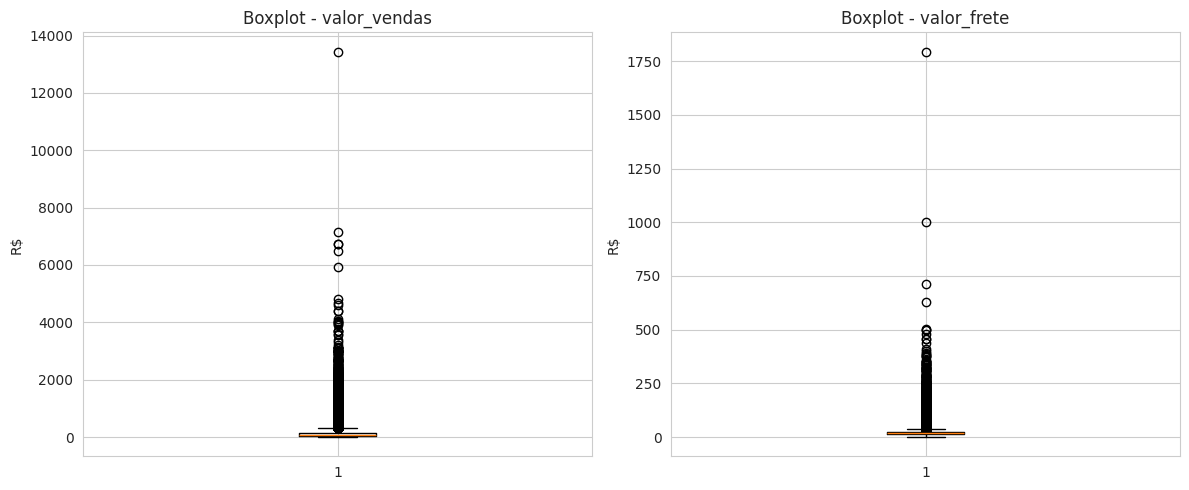

In [71]:
# fig: cria a figura e figsize define o tamanho dela:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico da esquerda (axes[0]):
axes[0].boxplot(base_pedidos['valor_vendas'], vert=True)
axes[0].set_title('Boxplot - valor_vendas')
axes[0].set_ylabel('R$')

# Gráfico da direita (axes[1]):
axes[1].boxplot(base_pedidos['valor_frete'], vert=True)
axes[1].set_title('Boxplot - valor_frete')
axes[1].set_ylabel('R$')

# Ajusta automaticamente os espaçamentos entre os dois gráficos:
plt.tight_layout()

# Exibição dos gráficos:
plt.show()

Visualizamos as duas variáveis lado a lado em boxplots, para "ver" de forma rápida a assimetria e os possíveis outliers que os números da tabela no item 3.1 já indicaram (média bem maior que a mediana).

In [72]:
# Cálculo dos limites inferior e superior de outlier pelo método do IQR (Intervalo Interquartil).
def limites_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    return limite_inferior, limite_superior

for coluna in ['valor_vendas', 'valor_frete']:
    lim_inf, lim_sup = limites_iqr(base_pedidos[coluna])

    n_outliers = ((base_pedidos[coluna] < lim_inf) | (base_pedidos[coluna] > lim_sup)).sum()
    pct_outliers = n_outliers / len(base_pedidos) * 100
    print(f'{coluna}:')
    print(f'  Limite inferior: R$ {lim_inf:.2f} | Limite superior: R$ {lim_sup:.2f}')
    print(f'  Pedidos fora do intervalo: {n_outliers} ({pct_outliers:.2f}% da base)')
    print()

valor_vendas:
  Limite inferior: R$ -110.10 | Limite superior: R$ 305.90
  Pedidos fora do intervalo: 7659 (7.94% da base)

valor_frete:
  Limite inferior: R$ -1.40 | Limite superior: R$ 39.27
  Pedidos fora do intervalo: 9697 (10.05% da base)



Os limites de outlier calculados pelo método do IQR resultaram em limites inferiores negativos (R\$ -110,10 para vendas e R\$ -1,40 para frete) — um artefato esperado da fórmula em bases com forte concentração de valores baixos, que não representa outliers reais "por baixo" (preço e frete não podem ser negativos). Todos os outliers identificados são, portanto, valores anormalmente altos: 7.659 pedidos (7,94% da base) em valor_vendas e 9.697 pedidos (10,05% da base) em valor_frete. A proporção de outliers ser maior no frete do que nas vendas, apesar de sua faixa "normal" ser mais estreita (até R\$ 39,27), reflete uma distribuição ainda mais concentrada em valores baixos. Como esses percentuais são expressivos (quase 1 em cada 10 pedidos), tratá-los como erro e removê-los descartaria uma parcela relevante e legítima da base.

In [73]:
# Inspeção dos 10 maiores valores de vendas e frete.
# O objetivo é verificar se parecem registros legítimos ou erros de cadastro.
print('10 maiores valores de venda:')
display(base_pedidos.nlargest(10, 'valor_vendas')[['order_id', 'valor_vendas', 'valor_frete', 'customer_state', 'mes_compra']])

print('\n10 maiores valores de frete:')
display(base_pedidos.nlargest(10, 'valor_frete')[['order_id', 'valor_vendas', 'valor_frete', 'customer_state', 'mes_compra']])

10 maiores valores de venda:


,order_id,valor_vendas,valor_frete,customer_state,mes_compra
13014,03caa2c082116e1d31e67e9ae3700499,13440.0,224.08,RJ,2017-09
64607,736e1922ae60d0d6a89247b851902527,7160.0,114.88,ES,2018-07
21526,0812eb902a67711a1cb742b3cdaa65ae,6735.0,194.31,MS,2017-02
27503,fefacc66af859508bf1a7934eab1e97f,6729.0,193.21,ES,2018-07
3413,f5136e38d1a14a4dbd87dff67da82701,6499.0,227.66,SP,2017-05
31370,2cc9089445046817a7539d90805e6e5a,5934.6,146.94,MG,2017-11
51774,a96610ab360d42a2e5335a3998b4718a,4799.0,151.34,RJ,2017-04
39132,199af31afc78c699f0dbf71fb178d4d4,4690.0,74.34,SP,2017-04
39146,8dbc85d1447242f3b127dda390d56e19,4590.0,91.78,PB,2018-06
10470,d2f270487125ddc41fd134c4003ad1d7,4400.0,45.50,RJ,2018-05



10 maiores valores de frete:


,order_id,valor_vendas,valor_frete,customer_state,mes_compra
19497,cf4659487be50c0c317cff3564c4a840,1050.00,1794.96,PB,2018-07
61787,2455cbeb73fd04b170ca2504662f95ce,419.40,1002.29,PR,2017-06
86119,cfed507ac357129f750f05a0d7d71b15,1380.00,711.33,MA,2018-02
15872,71dab1155600756af6de79de92e712e3,1361.89,626.64,BA,2018-02
27149,17784b9fbb37fb0bdc230d8ed6f6b355,840.00,502.98,BA,2018-03
84403,725cf8e9c24e679a8a5a32cb92c9ce1e,1570.00,497.42,PE,2017-06
18354,5bd06bab48e0423fc35d1c236d48a6bb,1520.00,497.08,PE,2017-05
19831,be382a9e1ed25128148b97d6bfdb21af,1559.92,479.28,RJ,2017-11
22565,c52c7fbe316b5b9d549e8a25206b8a1f,1161.00,458.73,GO,2018-03
95980,62073ec6b54b8e6322037fc0f3591ad3,859.66,456.47,RJ,2018-04


Os valores extremos foram mantidos na base.
Não há, entre as colunas disponíveis, evidência de erro de digitação ou duplicidade (ex.: preço e frete negativos, ou o mesmo pedido repetido); eles representam transações plausíveis. Como o método do IQR aponta uma proporção de outliers em `valor_vendas` e `valor_frete`, a correlação de Pearson — sensível a esses pontos — será complementada pela correlação de Spearman (baseada em postos, mais robusta a valores extremos) na Seção 3.6.

## 3.3 Categorias de produto (Questão 1)

**Questão:** Quais categorias de produtos concentram a maior parte da receita total?

Usamos `base_categoria` (nível de item) para somar o valor de venda (`price`) por categoria.

In [74]:
receita_categoria = (base_categoria.groupby('product_category_name', as_index=False)
                      .agg(receita_total=('price', 'sum'), qtd_itens=('price', 'count')))

# Ordenamos da maior para a menor receita, para já deixar as categorias mais relevantes no topo da tabela.
receita_categoria = receita_categoria.sort_values('receita_total', ascending=False)

# Calculamos a participação percentual de cada categoria na receita total:
receita_categoria['pct_receita'] = receita_categoria['receita_total'] / receita_categoria['receita_total'].sum() * 100

# Calculamos o percentual acumulado:
receita_categoria['pct_acumulado'] = receita_categoria['pct_receita'].cumsum()

# Recortamos só as 10 primeiras linhas para focar nas categorias mais relevantes, já que a base tem dezenas de categorias diferentes.
top10_categorias = receita_categoria.head(10)
top10_categorias

,product_category_name,receita_total,qtd_itens,pct_receita,pct_acumulado
11,beleza_saude,1233131.72,9465,9.326717,9.326717
67,relogios_presentes,1166176.98,5859,8.820309,18.147026
13,cama_mesa_banho,1023434.76,10953,7.740687,25.887713
33,esporte_lazer,954852.55,8431,7.221969,33.109682
45,informatica_acessorios,888724.61,7644,6.721815,39.831497
55,moveis_decoracao,711927.69,8160,5.384622,45.216119
73,utilidades_domesticas,615628.69,6795,4.656270,49.872389
27,cool_stuff,610204.10,3718,4.615242,54.487631
8,automotivo,578966.65,4140,4.378979,58.866610
12,brinquedos,471286.48,4030,3.564547,62.431157


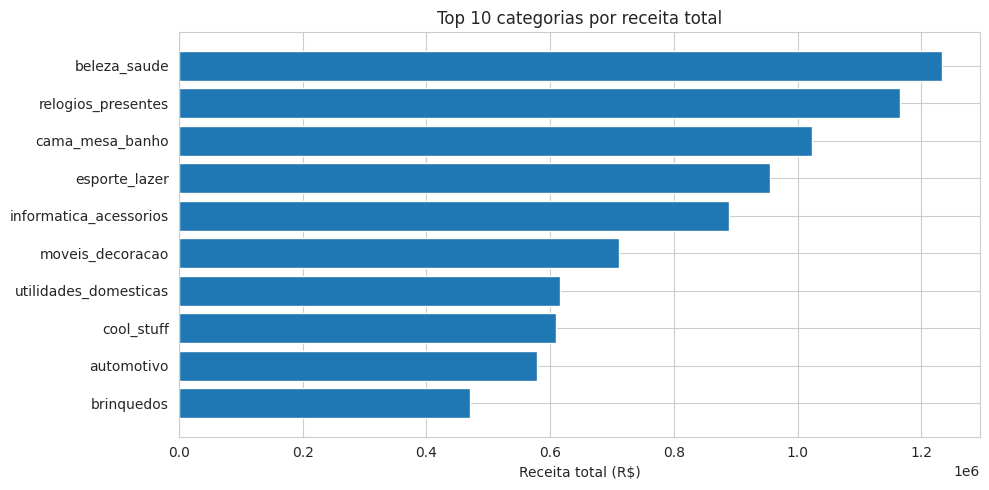

In [75]:
# Criação de gráfico de barras horizontais para melhor leitura dos rótulos das categorias:
plt.figure(figsize=(10, 5))

# .barth desenha o gráfico de barras na horizontal.
# Uso da expressão "[::-1]" inverte a ordem das linhas antes de plotar.
plt.barh(top10_categorias['product_category_name'][::-1], top10_categorias['receita_total'][::-1])

# Definição do título exibido no topo do gráfico:
plt.title('Top 10 categorias por receita total')

# Definição do rótulo do eixo X:
plt.xlabel('Receita total (R$)')

# Ajuste dos espaçamentos para nada ficar cortado:
plt.tight_layout()

# Exibição do gráfico:
plt.show()

As categorias beleza_saude, relogios_presentes e cama_mesa_banho lideraram a receita, e as 10 principais categorias concentraram 62,43% do total da receita.

## 3.4 Estados dos clientes (Questão 2)

**Questão:** Quais estados dos clientes apresentam maior valor total de vendas e maior ticket médio?

Usamos `base_pedidos` (nível de pedido), pois cada pedido já tem um único `customer_state` associado.

In [76]:
resumo_estado = (base_pedidos.groupby('customer_state', as_index=False)
                  .agg(receita_total=('valor_vendas', 'sum'),
                       qtd_pedidos=('order_id', 'nunique'),
                       ticket_medio=('valor_vendas', 'mean'))
                  .sort_values('receita_total', ascending=False))
resumo_estado

,customer_state,receita_total,qtd_pedidos,ticket_medio
25,SP,5067633.16,40501,125.123655
18,RJ,1759651.13,12350,142.481873
10,MG,1552481.83,11354,136.734352
22,RS,728897.47,5345,136.369966
17,PR,666063.51,4923,135.296264
23,SC,507012.13,3546,142.981424
4,BA,493584.14,3256,151.592181
6,DF,296498.41,2080,142.547312
8,GO,282836.70,1957,144.525652
7,ES,268643.45,1995,134.658371


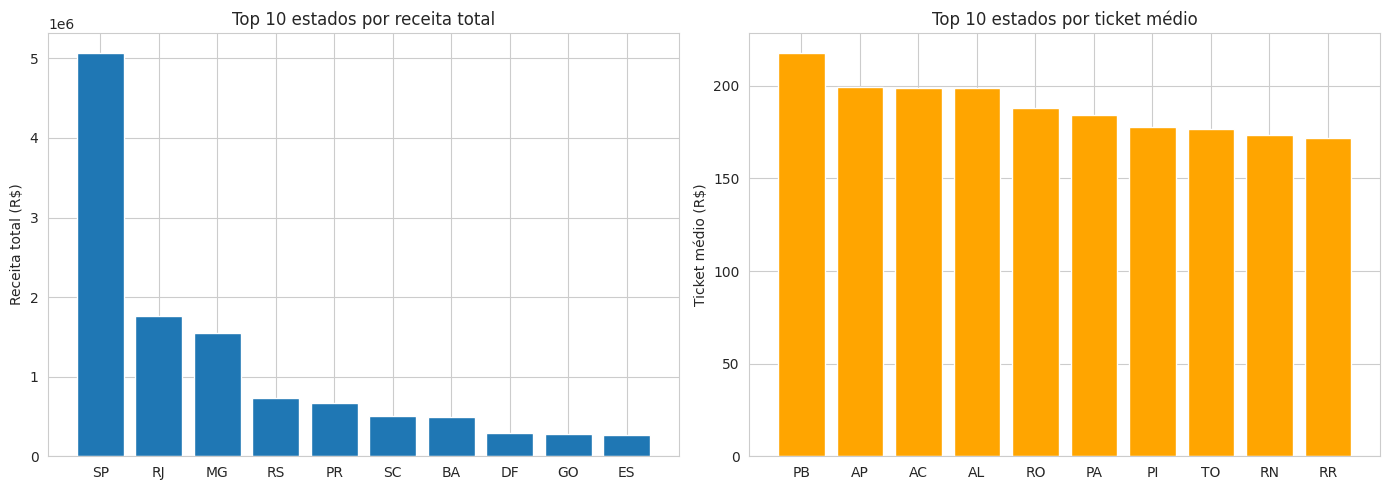

In [77]:
# fig: cria a figura e figsize define o tamanho dela.
# .subplots coloca um gráfico um ao lado do outro.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico da esquerda (axes[0]):
top10_estados = resumo_estado.head(10)

# .bar Desenha um gráfico de barras verticais.
axes[0].bar(top10_estados['customer_state'], top10_estados['receita_total'])

# Definição do texto do título exibido no topo do gráfico:
axes[0].set_title('Top 10 estados por receita total')

# Definição do texto do título exibido no eixo y:
axes[0].set_ylabel('Receita total (R$)')

# Gráfico da direita (axes[1]):
top10_ticket = resumo_estado.sort_values('ticket_medio', ascending=False).head(10)
axes[1].bar(top10_ticket['customer_state'], top10_ticket['ticket_medio'], color='orange')
axes[1].set_title('Top 10 estados por ticket médio')
axes[1].set_ylabel('Ticket médio (R$)')

# Ajuste automático dos espaçamentos entre os dois gráficos:
plt.tight_layout()

# Exibição dos gráficos:
plt.show()



SP lidera em receita total (R\$ 5.067.633,16) e concentra os pedidos, mas com o menor ticket médio da base (R\$ 125,12); estados do Norte/Nordeste com baixo volume (PB, AC, AP, AL) lideram em ticket médio, todos acima de R\$ 187 — um padrão de "muitos pedidos de menor valor" nos grandes centros versus "poucos pedidos de maior valor" nas regiões mais distantes.

## 3.5 Evolução temporal (Questão 3)

**Questão:** Como o volume e o valor das vendas variam ao longo do tempo?

Reaproveitamos `mes_compra`, calculada no Artefato 2, e a verificação de cobertura temporal feita na Seção 2.2.12.

In [78]:
# A ideia é não descartar esses pedidos da base inteira, só evitar que eles distorçam a leitura de
# tendência ao longo do tempo (por isso criamos uma cópia separada, em vez de sobrescrever base_pedidos).
# Exclusão dos meses:

meses_excluidos = ['2016-09', '2016-10', '2016-12']

# .astype(str) garante a comparação correta com a lista de texto acima, mesmo que mes_compra em base_pedidos ainda esteja como Period.
# O til (~) na frente inverte a condição: "mantenha as linhas cujo mês NÃO está na lista de excluídos".

base_pedidos_temporal = base_pedidos[
    ~base_pedidos['mes_compra'].astype(str).isin(meses_excluidos)
].copy()

print(f'Pedidos antes da exclusão: {len(base_pedidos)}')
print(f'Pedidos depois da exclusão: {len(base_pedidos_temporal)}')
print(f'Pedidos removidos: {len(base_pedidos) - len(base_pedidos_temporal)}')

# Agregamos por mês a partir da base já filtrada em "base_pedidos_temporal", para que os gráficos de evolução não incluam os meses excluídos.

evolucao_mensal = (base_pedidos_temporal.groupby('mes_compra', as_index=False)
                    .agg(qtd_pedidos=('order_id', 'nunique'),
                         receita_total=('valor_vendas', 'sum'),
                         ticket_medio=('valor_vendas', 'mean'))
                    .sort_values('mes_compra'))

# Garante que o eixo X do gráfico receba texto, não Period:
evolucao_mensal['mes_compra'] = evolucao_mensal['mes_compra'].astype(str)

evolucao_mensal

Pedidos antes da exclusão: 96478
Pedidos depois da exclusão: 96211
Pedidos removidos: 267


,mes_compra,qtd_pedidos,receita_total,ticket_medio
0,2017-01,750,111798.36,149.064480
1,2017-02,1653,234223.40,141.695947
2,2017-03,2546,359198.85,141.083602
3,2017-04,2303,340669.68,147.924307
4,2017-05,3546,489338.25,137.997250
5,2017-06,3135,421923.37,134.584807
6,2017-07,3872,481604.52,124.381333
7,2017-08,4193,554699.70,132.291844
8,2017-09,4150,607399.67,146.361366
9,2017-10,4478,648247.65,144.762762


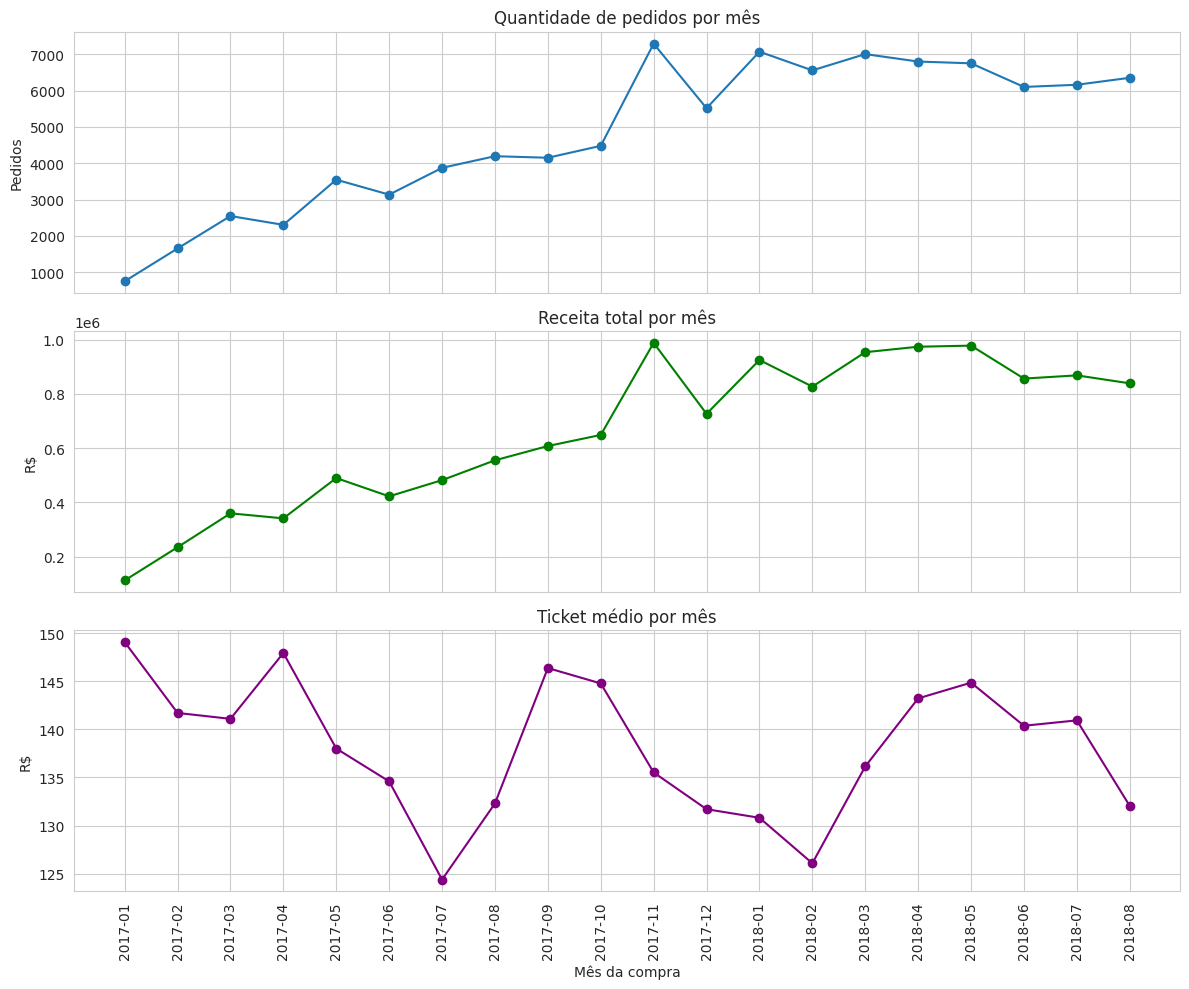

In [79]:
# Três gráficos de linha empilhados (um por métrica), compartilhando o mesmo eixo X (sharex=True)
# Assim dá para comparar visualmente, mês a mês, quantidade de pedidos, receita e ticket médio sem repetir os rótulos do eixo X três vezes.

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(evolucao_mensal['mes_compra'], evolucao_mensal['qtd_pedidos'], marker='o')
axes[0].set_title('Quantidade de pedidos por mês')
axes[0].set_ylabel('Pedidos')

# Cor diferente em cada gráfico só para facilitar a leitura visual:
axes[1].plot(evolucao_mensal['mes_compra'], evolucao_mensal['receita_total'], marker='o', color='green')
axes[1].set_title('Receita total por mês')
axes[1].set_ylabel('R$')

axes[2].plot(evolucao_mensal['mes_compra'], evolucao_mensal['ticket_medio'], marker='o', color='purple')
axes[2].set_title('Ticket médio por mês')
axes[2].set_ylabel('R$')
axes[2].set_xlabel('Mês da compra')

# Gira os rótulos do eixo X em 90° porque temos ~20 meses — sem isso, os textos ('2017-01', '2017-02'...) ficariam sobrepostos e ilegíveis.
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Após excluir os meses: 2016-09, 2016-10 e 2016-12, o volume de pedidos cresceu fortemente ao longo de 2017 (de 750 para um pico de 7.289 em novembro, provável efeito Black Friday), estabilizando-se em 2018 num patamar mais alto (~6.000-7.300 pedidos/mês). O ticket médio permaneceu estável durante todo o período, indicando que o crescimento veio do volume de pedidos, não do valor médio por pedido.

## 3.6 Relação entre frete e valor de vendas (Questão 4)

**Questão:** Existe associação entre o valor do frete e o valor de vendas por pedido?

Como vimos na Seção 3.2, ambas as variáveis têm valores extremos relevantes. Por isso, calculamos duas medidas de correlação:

- **Pearson (r):** mede associação *linear*; é sensível a valores extremos.
- **Spearman (rho):** utiliza a posição/ranking dos valores e pode ser útil quando a relação não é bem representada por uma linha ou quando há forte assimetria.

Também aplicamos um teste de hipótese para a correlação de Pearson:
- H0 (hipótese nula): a correlação populacional entre frete e valor de vendas é igual a zero (não há associação linear).
- H1 (hipótese alternativa): a correlação populacional é diferente de zero.
- Nível de significância adotado: α = 0,05.

In [80]:
pearson_r, pearson_p = stats.pearsonr(base_pedidos['valor_frete'], base_pedidos['valor_vendas'])
spearman_r, spearman_p = stats.spearmanr(base_pedidos['valor_frete'], base_pedidos['valor_vendas'])

print(f'Correlação de Pearson:  r    = {pearson_r:.3f}  (p-valor = {pearson_p:.4f})')
print(f'Correlação de Spearman: rho  = {spearman_r:.3f}  (p-valor = {spearman_p:.4f})')

if pearson_p < 0.05:
    print('\nComo p-valor < 0,05, rejeitamos H0: há evidência estatística de associação linear entre as variáveis.')
else:
    print('\nComo p-valor >= 0,05, não rejeitamos H0: não há evidência estatística suficiente de associação linear.')

Correlação de Pearson:  r    = 0.411  (p-valor = 0.0000)
Correlação de Spearman: rho  = 0.470  (p-valor = 0.0000)

Como p-valor < 0,05, rejeitamos H0: há evidência estatística de associação linear entre as variáveis.


O coeficiente de Pearson (r = 0,411) indica uma associação linear moderada e positiva entre `valor_frete` e `valor_vendas`: pedidos com frete mais alto tendem a estar associados a valores de venda mais altos, e vice-versa — a correlação não indica qual variável "leva" a outra, apenas que as duas se movem na mesma direção. A correlação de Spearman (rho = 0,470), ligeiramente maior que a de Pearson, sugere que essa associação é um pouco mais forte quando medida pela ordenação dos valores (menos sensível aos outliers identificados na Seção 3.2) do que pela relação estritamente linear. O teste de hipótese (p-valor < 0,0001) indica que é muito improvável que essa associação seja fruto do acaso: há evidência estatística de que as duas variáveis não são independentes entre si.

In [81]:
# Reta de regressão simples: valor_vendas em função de valor_frete
# linregress() devolve, de uma vez, tudo que precisamos para descrever a reta e avaliar o quanto ela explica os dados.
inclinacao, intercepto, r_regressao, p_regressao, erro_padrao = stats.linregress(
    base_pedidos['valor_frete'], base_pedidos['valor_vendas']
)

print(f'Reta ajustada: valor_vendas = {intercepto:.2f} + {inclinacao:.2f} * valor_frete')
print(f'R (coeficiente de correlação da regressão): {r_regressao:.3f}')
print(f'R² (proporção da variância explicada): {r_regressao**2:.3f}')

Reta ajustada: valor_vendas = 46.20 + 3.99 * valor_frete
R (coeficiente de correlação da regressão): 0.411
R² (proporção da variância explicada): 0.169


O Coeficiente Angular (3.99): Significa que, para cada aumento de $R\$ 1,00$ no valor do frete, o valor total de vendas do pedido sofre um acréscimo médio estimado de R\$ 3,99.

O Intercepto (46.20): É o valor base estimado da venda quando o frete fosse teoricamente zero (embora seja um parâmetro matemático do modelo, serve de âncora para a linha).

O $R^2$ de 0,169 quer dizer que 16,9% da variância no valor de vendas é explicada pelo valor do frete.

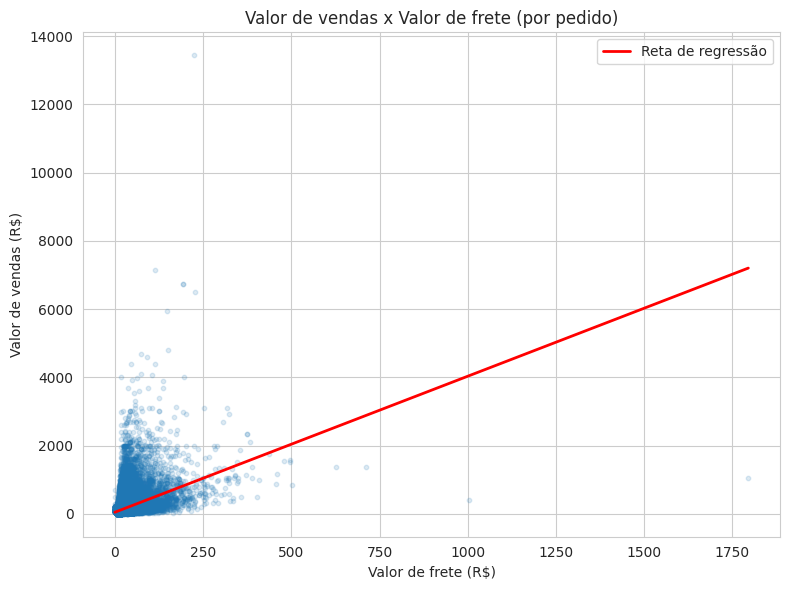

In [82]:
# Visualizamos a nuvem de pontos (cada ponto = um pedido) junto com a reta ajustada,
# para ver "de olho" se a reta realmente descreve bem o padrão dos dados ou se, existe um formato de leque (dispersão
# crescendo com o frete) que a reta sozinha não captura.
plt.figure(figsize=(8, 6))

# alpha=0.15 deixa os pontos parcialmente transparentes, permitindo enxergar onde os pontos se concentram mais (áreas mais "escuras" = mais pedidos ali).
plt.scatter(base_pedidos['valor_frete'], base_pedidos['valor_vendas'], alpha=0.15, s=10)

# Ordenamos os valores de frete antes de calcular a reta, para que o plt.plot desenhe a linha da esquerda para a direita, sem "voltar"
# no meio do caminho (o que aconteceria se os pontos não estivessem em ordem crescente de x).
x_linha = base_pedidos['valor_frete'].sort_values()
y_linha = intercepto + inclinacao * x_linha
plt.plot(x_linha, y_linha, color='red', linewidth=2, label='Reta de regressão')

plt.title('Valor de vendas x Valor de frete (por pedido)')
plt.xlabel('Valor de frete (R$)')
plt.ylabel('Valor de vendas (R$)')
plt.legend()
plt.tight_layout()
plt.show()

Associação moderada e positiva entre valor de frete e valor de vendas (Pearson r = 0,411; Spearman rho = 0,470; p < 0,0001), com o frete explicando 16,9% da variação das vendas (R²). O padrão é consistente com pedidos de maior valor/porte gerando tanto frete quanto venda mais altos — uma associação estatística, não uma relação de causa e efeito.

### 3.7 Frete zero: dado de apoio para a Seção 4

Antes de propor recomendações sobre estratégias de frete grátis (Seção 4.3), verificamos qual fração dos pedidos já tem valor de frete igual a zero na base atual — um dado objetivo, diretamente calculável, que evita propor uma recomendação apoiada em um número estimado.

In [83]:
pct_frete_zero = (base_pedidos['valor_frete'] == 0).mean() * 100
qtd_frete_zero = (base_pedidos['valor_frete'] == 0).sum()
print(f'Pedidos com valor de frete igual a zero: {qtd_frete_zero} ({pct_frete_zero:.2f}% da base)')

Pedidos com valor de frete igual a zero: 336 (0.35% da base)


# Artefato 4 – Consolidação e Comunicação dos Resultados

## 4.1 Síntese dos principais resultados

O artefato 3 explorou as quatro questões de investigação definidas no Artefato 1, combinando estatística descritiva, visualizações e testes de hipótese para caracterizar o comportamento das vendas na base Olist.

- **Categorias (Questão 1):**

A receita está moderadamente concentrada — as 10 categorias líderes respondem por 62,43% do total, com destaque para beleza_saude (9,33%), relogios_presentes (8,82%) e cama_mesa_banho (7,74%). Ficou evidente que volume vendido e receita gerada nem sempre andam juntos: categorias de alto giro e baixo ticket (como cama_mesa_banho, ~R\$ 93/item) convivem com categorias de baixo giro e alto ticket (como relogios_presentes, ~R\$ 199/item), ambas relevantes para o faturamento por caminhos diferentes.

- **Estados (Questão 2):**

SP lidera tanto em receita (38,33%) quanto em volume de pedidos (41,98%), mas justamente por concentrar tantos pedidos apresenta o menor ticket médio da base (R\$ 125,12). O padrão se inverte nos estados de maior ticket médio (PB, AC, AP, AL — todos acima de R\$ 187), que têm baixíssimo volume de pedidos, sugerindo compras mais pontuais e de maior valor nas regiões mais distantes dos centros de distribuição.

- **Evolução temporal (Questão 3):**

Após excluir da leitura os meses: 2016-09, 2016-10 e 2016-12, a série de 2017-01 a 2018-08 mostra crescimento acelerado do volume de pedidos ao longo de 2017, com pico em novembro (a coincidência com a Black Friday é uma hipótese contextual, não um efeito comprovado) seguido de queda em dezembro, e uma estabilização em 2018 num patamar mais alto (~6.000-7.300 pedidos/mês). O ticket médio permaneceu estável durante todo o período, indicando que o crescimento veio do volume de pedidos, e não de um aumento no valor médio por pedido.

- **Frete x Vendas (Questão 4):**

Existe uma associação moderada e positiva entre valor de frete e valor de vendas (Pearson r = 0,411; Spearman rho = 0,470; p < 0,0001), com o frete explicando 16,9% da variação das vendas (R²). O padrão observado é consistente com pedidos de maior porte gerando tanto frete quanto venda mais altos — uma associação estatística, não uma relação de causa e efeito.

## 4.2 Conclusões

Retomando a pergunta de negócio — quais fatores estão associados ao valor total de vendas dos pedidos entregues na base Olist —, a análise permite concluir que:

* A **categoria do produto** está associada ao valor de vendas de forma moderada: um grupo de 10 categorias (entre as 74 identificadas) concentra 62,43% da receita, sem que nenhuma categoria isolada domine o total.
* O **estado do cliente** está associado tanto ao volume quanto ao ticket médio das vendas, mas em direções opostas: estados de maior volume (SP, RJ, MG) apresentam ticket médio mais baixo, enquanto estados de menor volume (PB, AP, AC, AL) apresentam ticket médio mais alto.
* O **mês da compra** está associado ao volume de pedidos, com crescimento ao longo de 2017 e estabilização em 2018 em um patamar mais alto; o ticket médio, no entanto, não acompanhou essa variação, permanecendo relativamente estável ao longo de todo o período observado.
* O **valor do frete** está associado ao valor de vendas de forma moderada e estatisticamente significativa (Pearson r = 0,411; Spearman rho = 0,470; p < 0,0001), mas essa associação explica menos de 17% da variação total das vendas (R² = 0,169) — outros fatores não incluídos neste estudo têm peso relevante sobre o valor de cada pedido.

Em conjunto, os quatro fatores investigados apresentam associação com o valor de vendas, porém em graus distintos e sem indicar relação de causa e efeito. Essas evidências respondem à pergunta de negócio proposta no Artefato 1 e fornecem a base factual para as recomendações apresentadas na seção seguinte.

## 4.3 Recomendações Gerenciais

**1. Priorizar ações comerciais e logísticas por região, não de forma homogênea.**

Como o valor de vendas e o ticket médio variam de forma expressiva entre estados (Seção 3.4), a rede não deveria tratar todo o território de forma uniforme. Em SP, RJ e MG — que concentram a maior parte do volume de pedidos — o foco poderia ser em eficiência operacional e redução de frete, já que o ticket médio ali é mais baixo e o volume é alto. Já em estados de menor volume, mas ticket médio mais alto (como PB, AP e AC), vale investigar se há espaço para ampliar o alcance comercial nessas regiões, dado que o cliente que já compra ali tende a gastar mais por pedido — possivelmente consolidando vários itens numa mesma compra para diluir o custo do frete. **Essa explicação é uma hipótese, não um fato observado diretamente nos dados disponíveis**, e mereceria investigação futura com dados adicionais (como frequência de compra por cliente).

**2. Usar o frete como sinal indireto de porte do pedido — não necessariamente como alavanca isolada de precificação.**

A correlação moderada e significativa entre `valor_frete` e `valor_vendas` (Pearson r = 0,411; p < 0,0001, Seção 3.6) mostra que pedidos maiores tendem a ter frete mais alto. Isso sugere que ações de frete grátis a partir de um valor mínimo de compra podem incentivar o cliente a aumentar o valor do carrinho para atingir esse patamar. O cálculo da Seção 3.7 mostra qual fração dos pedidos já tem frete zero atualmente, o que ajuda a dimensionar o espaço para uma campanha nesse sentido antes de propor metas específicas.

**3. Planejar estoque e campanhas considerando a sazonalidade de volume, não de ticket médio.**

Como o volume de pedidos variou de forma expressiva ao longo do período analisado — de 750 pedidos em janeiro de 2017 (mês de cobertura parcial da base) a um pico de 7.289 em novembro de 2017 (Seção 3.5) —, enquanto o ticket médio se manteve relativamente estável (entre R\$ 124,38 e R\$ 149,06), o planejamento de estoque, logística e campanhas promocionais deveria priorizar a previsão de picos e vales de demanda por mês, em vez de tentar elevar o valor médio do pedido em períodos específicos.

**4. Ampliar o mix de categorias de médio desempenho.**

A receita está distribuída por um número relativamente amplo de categorias — as 10 líderes somam 62,43% do total, uma concentração moderada, não extrema (Seção 3.3) —, o que indica que a rede não depende de poucas categorias "carro-chefe". Isso sugere espaço para investir também nas categorias de desempenho intermediário, ampliando a diversificação da receita e reduzindo a dependência das três categorias líderes.

**5. Investigar a causa do pico de novembro antes de repeti-lo como estratégia.**

O pico de pedidos observado em novembro de 2017 ocorre no mesmo período em que normalmente acontece a Black Friday no Brasil, mas essa associação com a Black Friday é uma **hipótese de interpretação** — a base de dados utilizada não contém informação sobre campanhas promocionais ou datas de eventos comerciais. Antes de replicar ações de marketing baseadas nesse pico em novembros futuros, recomenda-se confirmar a causa junto às áreas de marketing e comercial responsáveis pelo período analisado.

## 4.4 Limitações do Estudo

* **Cobertura temporal desigual**: três meses do início da série (2016-09, 2016-10 e 2016-12) tinham cobertura muito baixa e foram excluídos da análise de evolução temporal (Seção 2.2.12). Janeiro de 2017 foi mantido, mas com cobertura parcial (87,1% do mês), e agosto de 2018 (último mês da base) tem cobertura de 93,5%. Conclusões sobre tendência nesses dois meses específicos devem ser vistas com cautela; os demais meses da série têm cobertura de 100%, incluindo setembro de 2017, cuja leve queda de pedidos em relação a agosto de 2017 reflete variação real de volume, não uma limitação de cobertura da base.

* **Uso de apenas 4 das 9 tabelas disponíveis**: não foram incorporadas informações de pagamento (`olist_order_payments_dataset`), avaliação do cliente (`olist_order_reviews_dataset`), vendedor (`olist_sellers_dataset`) e geolocalização (`olist_geolocation_dataset`), que poderiam agregar variáveis explicativas relevantes (forma de pagamento, satisfação, distância vendedor-cliente).

* **Associações, não causalidade**: as correlações e os testes de hipóteses aplicados indicam associação estatística entre variáveis, não relação de causa e efeito. Por exemplo, a correlação entre frete e valor de vendas pode refletir características do produto (peso, tamanho) que se relacionam com ambas as variáveis, e não uma causando a outra diretamente.

* **Métricas por estado sensíveis ao tamanho da amostra**: estados com poucos pedidos (como AP, com 67 pedidos) têm ticket médio mais sujeito a distorção por poucos pedidos de valor atípico, o que exige cautela ao comparar diretamente com estados de maior volume.

* **Ausência de dados de custo e margem**: a análise trata apenas do valor de vendas (receita), sem considerar custo dos produtos ou margem de contribuição — fatores essenciais para transformar as recomendações comerciais em decisões de rentabilidade.

* **Valores extremos**: os outliers de `valor_vendas` (mediana R\$ 86,58 contra máximo de R\$ 13.440,00) e `valor_frete` (mediana R\$ 17,17 contra máximo de R\$ 1.794,96) foram mantidos por não haver evidência de erro; ainda assim, eles influenciam medidas sensíveis como a média e a correlação de Pearson, o que motivou o uso complementar da mediana e da correlação de Spearman.

## 4.5 Trabalhos futuros e possibilidades de continuidade

* Incorporar as bases de pagamento e avaliação do cliente para investigar se a forma de pagamento ou a satisfação do cliente também se associam ao valor de vendas.

* Aplicar modelos de regressão múltipla (ou modelos de machine learning) para estimar o efeito conjunto e controlado de frete, estado, mês e categoria sobre o valor de vendas, em vez de analisá-los apenas dois a dois.

* Investigar a relação entre a localização do vendedor (olist_sellers_dataset) e o valor do frete, já que a distância entre vendedor e cliente é um forte candidato a explicar parte da variação de frete observada.

* Repetir a análise de sazonalidade com uma base que cubra ciclos anuais completos, para diferenciar sazonalidade real de limitação de cobertura dos dados.

## 4.6 Referências

- OLIST. **Brazilian E-Commerce Public Dataset by Olist**. Kaggle, 2018. Disponível em: <https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce>.
- McKINNEY, W. **Python for Data Analysis**. O'Reilly Media (documentação oficial do pandas: <https://pandas.pydata.org/docs/>).
- Documentação oficial do NumPy: <https://numpy.org/doc/>.
- Documentação oficial do Matplotlib: <https://matplotlib.org/stable/>.
- Documentação oficial do Seaborn: <https://seaborn.pydata.org/>.
- Documentação oficial do SciPy (scipy.stats): <https://docs.scipy.org/doc/scipy/reference/stats.html>.
- Material didático das disciplinas de Python para Dados e de Probabilidade e Estatística — Pós-Graduação em Análise Estratégica de Dados, IFMG Campus Formiga.